# Results Analysis: Metrics, Visualisation and Statistical Tests
## Comparing all models on the same test images

*COMP6001 - Computer Vision and Multimodal Machine Learning - Final Project*

## Section 1 - Objective of this Notebook

The earlier notebooks trained a custom CNN, seven benchmark methods and a CNN written from scratch. Each produced a table of scores, but a table of numbers does not yet answer the real questions: *Which model is best? Is the difference real or only chance? Where do the models fail? What does it mean for the project?* This notebook answers them by analysing the saved test-set predictions of **all** models. It

1. computes a set of **evaluation metrics** that are suitable for an imbalanced multi-class problem (Section 4);
2. attaches **confidence intervals** to the scores (Section 5);
3. applies **statistical tests** to decide which differences are significant (Section 6);
4. analyses the results **per class** (Section 7) and the **errors** (Section 8) and the model **confidence** (Section 9);
5. weighs quality against cost and summarises the findings of the whole project (Sections 10 - 11).

The notebook needs the prediction files in `results/predictions/`, which the earlier notebooks create (at least `benchmark_methods.ipynb`; `custom_cnn.ipynb` and `implementation_from_scratch.ipynb` add more models). All text that quotes numbers in Section 11 is generated from the data, so it always matches the results of your run.

## Section 2 - Evaluation Metrics: Definitions and Why They Were Chosen

Let $C$ be the confusion matrix on $N$ test images with $K$ classes, where $C_{ij}$ counts images of true class $i$ predicted as $j$. Write $TP_c=C_{cc}$, $FP_c=\sum_{i\ne c}C_{ic}$ and $FN_c=\sum_{j\ne c}C_{cj}$.

| Metric | Definition | Why it is used |
|---|---|---|
| **Accuracy** | $\dfrac{\sum_c TP_c}{N}$ | Familiar and comparable with the literature, but dominated by large classes |
| **Macro precision** | $\dfrac1K\sum_c \dfrac{TP_c}{TP_c+FP_c}$ | Of the images assigned to a class, how many were right, averaged over classes |
| **Macro recall** (= balanced accuracy) | $\dfrac1K\sum_c \dfrac{TP_c}{TP_c+FN_c}$ | Of the images of a class, how many were found; every class counts equally |
| **Macro-F1** | $\dfrac1K\sum_c \dfrac{2P_cR_c}{P_c+R_c}$ | The main metric: balances precision and recall and treats small and large classes alike, which matters because the largest class has about 35 times more images than the smallest |
| **Weighted F1** | $\sum_c \dfrac{n_c}{N}\,\text{F1}_c$ | F1 weighted by class size; shows how much the large classes alone explain |
| **Cohen's kappa** | $\kappa=\dfrac{p_o-p_e}{1-p_e}$, with $p_o$ the accuracy and $p_e=\sum_c \frac{(\text{true}_c)(\text{pred}_c)}{N^2}$ | Accuracy corrected for agreement expected by chance |
| **Matthews correlation coefficient (MCC)** | $\dfrac{c\,s-\sum_k p_k t_k}{\sqrt{(s^2-\sum_k p_k^2)(s^2-\sum_k t_k^2)}}$, with $c=\operatorname{tr}C$, $s=N$, $p_k$ predicted and $t_k$ true counts | A single balanced summary of the whole confusion matrix, robust to imbalance (Gorodkin, 2004) |

Accuracy alone would hide poor performance on small classes, which is why macro-F1 and MCC are the main metrics.

**Statistical tools.**

* **Bootstrap confidence interval.** The test set is resampled with replacement $B$ times (the *same* resampled images for every model, so comparisons stay paired); each metric is recomputed, and the 2.5th and 97.5th percentiles give a 95 % interval (Efron and Tibshirani, 1993). It shows how much a score could change with a different sample of test images.
* **Cochran's Q test** (omnibus). Do the $k$ models differ at all in their per-image correctness? With $x_{ij}\in\{0,1\}$ the correctness of model $j$ on image $i$, column totals $C_j$, row totals $R_i$ and grand total $T$,

$$
Q=\frac{(k-1)\big[\,k\sum_j C_j^{2}-T^{2}\,\big]}{k\,T-\sum_i R_i^{2}}\ \sim\ \chi^2_{k-1}\ \text{(under the null hypothesis that all models are equally accurate)}.
$$

* **McNemar's test** (pairwise; McNemar, 1947; recommended for comparing two classifiers on one test set by Dietterich, 1998). For two models, let $b$ be the number of images that only model A classifies correctly and $c$ the number that only model B classifies correctly. Images both get right or both get wrong carry no information about the difference. With continuity correction,

$$
\chi^2=\frac{(|b-c|-1)^2}{b+c}\ \sim\ \chi^2_1,
$$

and when $b+c<25$ the exact two-sided binomial test with success probability $0.5$ is used instead. A small $p$-value means the two models make different errors in a way that favours one of them.
* **Holm correction** (Holm, 1979). Comparing many pairs makes false positives likely, so the $m$ $p$-values are sorted, $p_{(1)}\le\dots\le p_{(m)}$, and adjusted to $\tilde p_{(i)}=\max_{j\le i}\min\big(1,(m-j+1)\,p_{(j)}\big)$; a difference is called significant when $\tilde p<0.05$. Holm controls the family-wise error rate and is never less powerful than the Bonferroni correction.

## Section 3 - Setup and Loading the Predictions

Libraries and folders as in the other notebooks. Figures and tables are saved in `results/analysis/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
from sklearn.metrics import cohen_kappa_score

SEED = 42
N_BOOT = 2000                      # bootstrap resamples
ALPHA = 0.05

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT_DIR / "data"
PRED_DIR = ROOT_DIR / "results" / "predictions"
BENCH_DIR = ROOT_DIR / "results" / "benchmarks"
RESULTS = ROOT_DIR / "results" / "analysis"
RESULTS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

def save_show(name):
    plt.tight_layout()
    plt.savefig(RESULTS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

Every model saved a file `<model>_test_predictions.csv` with the columns `path`, `y_true` and `y_pred` for the test images. The cell below reads all of them, gives each a readable name, and keeps only the test images that **every** model predicted, so all models are compared on exactly the same images (in a normal run this is the full test set; in a quick test run it is a small subset). It also reads the class names, crops and training-set class sizes from `data/splits.csv`.

In [2]:
NAMES = {
    "custom_cnn": "Custom CNN (ours)", "custom_cnn_weighted": "Custom CNN, class-weighted",
    "numpy_cnn_from_scratch": "NumPy CNN from scratch (32x32)",
    "svm_hand_crafted": "SVM hand-crafted", "random_forest_hand_crafted": "Random forest hand-crafted",
    "svm_deep_features": "SVM deep-features", "random_forest_deep_features": "Random forest deep-features",
    "resnet18_fine_tuned": "ResNet18 fine-tuned", "logistic_regression_image_only": "Logistic regression image-only",
    "fusion_image_crop": "Fusion image + crop", "image_text_alignment": "Image-text alignment",
}
files = sorted(PRED_DIR.glob("*_test_predictions.csv"))
assert files, "No prediction files found in results/predictions/ - run the model notebooks first."

preds = {}
for f in files:
    slug = f.name.replace("_test_predictions.csv", "")
    preds[NAMES.get(slug, slug)] = pd.read_csv(f).drop_duplicates("path").set_index("path")

common = sorted(set.intersection(*[set(p.index) for p in preds.values()]))
largest = max(len(p) for p in preds.values())
print(f"{len(preds)} models found; {len(common)} test images are shared by all (largest file: {largest})")
if len(common) < 0.5 * largest:
    print("WARNING: the models were evaluated on different test subsets (quick-test run?). Re-run the notebooks with QUICK_TEST = False.")

y_true = preds[next(iter(preds))].loc[common, "y_true"].values.astype(int)
Yp = {n: p.loc[common, "y_pred"].values.astype(int) for n, p in preds.items()}
for n, p in preds.items():
    assert (p.loc[common, "y_true"].values == y_true).all(), f"{n}: true labels do not match the other models"

meta = pd.read_csv(DATA_DIR / "splits.csv")
class_info = meta.drop_duplicates("label").sort_values("label")
class_names = class_info["class_name"].tolist()
class_crop = class_info["crop"].tolist()
class_healthy = class_info["is_healthy"].values.astype(bool)
train_counts = meta[meta["split"] == "train"].groupby("label").size().reindex(range(len(class_names))).fillna(0).values
K, N = len(class_names), len(common)
print(f"{K} classes, {N} test images, models: {list(preds)}")

10 models found; 1020 test images are shared by all (largest file: 2349)
17 classes, 1020 test images, models: ['Custom CNN (ours)', 'Fusion image + crop', 'Image-text alignment', 'Logistic regression image-only', 'NumPy CNN from scratch (32x32)', 'Random forest deep-features', 'Random forest hand-crafted', 'ResNet18 fine-tuned', 'SVM deep-features', 'SVM hand-crafted']


## Section 4 - Evaluation Metrics for All Models

All metrics of Section 2 are computed from each model's confusion matrix with fast NumPy code (`np.bincount`), which is also what the bootstrap in Section 5 reuses thousands of times. The table is sorted by macro-F1. The last column, **rank**, is the position by macro-F1.

In [3]:
def confusion(yt, yp, K):
    return np.bincount(yt * K + yp, minlength=K * K).reshape(K, K)

def metrics_from_cm(C):
    tp = np.diag(C).astype(float)
    fp, fn = C.sum(0) - tp, C.sum(1) - tp
    n = C.sum()
    prec = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=(tp + fp) > 0)
    rec = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=(tp + fn) > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    t, p = C.sum(1).astype(float), C.sum(0).astype(float)
    mcc_den = np.sqrt((n ** 2 - (p ** 2).sum()) * (n ** 2 - (t ** 2).sum()))
    pe = (t * p).sum() / n ** 2
    acc = tp.sum() / n
    return dict(accuracy=acc, macro_precision=prec.mean(), macro_recall=rec.mean(), macro_f1=f1.mean(),
                weighted_f1=(f1 * t / n).sum(), kappa=(acc - pe) / (1 - pe) if pe < 1 else 0.0,
                mcc=(tp.sum() * n - (t * p).sum()) / mcc_den if mcc_den > 0 else 0.0), prec, rec, f1

rows, per_class_f1, per_class_rec = [], {}, {}
for n, yp in Yp.items():
    m, prec, rec, f1 = metrics_from_cm(confusion(y_true, yp, K))
    rows.append(dict(model=n, **m))
    per_class_f1[n], per_class_rec[n] = f1, rec

table = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
table.insert(1, "rank", range(1, len(table) + 1))
table.to_csv(RESULTS / "metrics_all_models.csv", index=False)
display(table.round(4))

# sanity check against scikit-learn on one model
assert abs(cohen_kappa_score(y_true, Yp[table.loc[0, "model"]]) - table.loc[0, "kappa"]) < 1e-9, "kappa mismatch"

,model,rank,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,kappa,mcc
0,ResNet18 fine-tuned,1,0.9902,0.9914,0.9907,0.9909,0.9902,0.9891,0.9891
1,Custom CNN (ours),2,0.9765,0.9762,0.9642,0.9690,0.9762,0.9739,0.9739
2,SVM deep-features,3,0.9775,0.9674,0.9723,0.9690,0.9775,0.9750,0.9750
3,Logistic regression image-only,4,0.9441,0.9420,0.9416,0.9414,0.9440,0.9380,0.9380
4,Fusion image + crop,5,0.9471,0.9399,0.9438,0.9409,0.9467,0.9412,0.9413
5,Image-text alignment,6,0.9392,0.9182,0.9223,0.9196,0.9389,0.9325,0.9326
6,Random forest deep-features,7,0.8765,0.9073,0.7807,0.8125,0.8677,0.8620,0.8629
7,SVM hand-crafted,8,0.8696,0.8603,0.7861,0.8082,0.8676,0.8547,0.8550
8,Random forest hand-crafted,9,0.7902,0.7643,0.6266,0.6557,0.7718,0.7622,0.7671
9,NumPy CNN from scratch (32x32),10,0.5461,0.5151,0.5955,0.5131,0.5684,0.5085,0.5132


**Check.** The assertion above compares our fast implementation with scikit-learn for Cohen's kappa. A large gap between accuracy and macro-F1 (or MCC) for a model means it does well on the big classes but poorly on small ones.

## Section 5 - Confidence Intervals by Bootstrap

A single score such as 0.97 depends on the particular test images. The cell draws `N_BOOT` bootstrap samples of the test images, recomputes accuracy and macro-F1 for every model on each sample (the **same** sample for all models, so the comparison is paired), and reports the 95 % percentile interval. The chart shows the score of each model with its interval: **models whose intervals do not overlap clearly differ; overlapping intervals do not by themselves prove the models are equal**, which is why Section 6 uses paired tests.

,model,accuracy,accuracy_low,accuracy_high,macro_f1,macro_f1_low,macro_f1_high
0,ResNet18 fine-tuned,0.9902,0.9843,0.9961,0.9909,0.9844,0.9962
1,Custom CNN (ours),0.9765,0.9667,0.9853,0.9690,0.9463,0.9828
2,SVM deep-features,0.9775,0.9676,0.9863,0.9690,0.9510,0.9819
3,Logistic regression image-only,0.9441,0.9304,0.9578,0.9414,0.9252,0.9554
4,Fusion image + crop,0.9471,0.9333,0.9608,0.9409,0.9213,0.9562
5,Image-text alignment,0.9392,0.9245,0.9539,0.9196,0.8864,0.9423
6,Random forest deep-features,0.8765,0.8569,0.8971,0.8125,0.7604,0.8478
7,SVM hand-crafted,0.8696,0.8480,0.8902,0.8082,0.7581,0.8432
8,Random forest hand-crafted,0.7902,0.7657,0.8147,0.6557,0.6230,0.6843
9,NumPy CNN from scratch (32x32),0.5461,0.5157,0.5775,0.5131,0.4762,0.5455


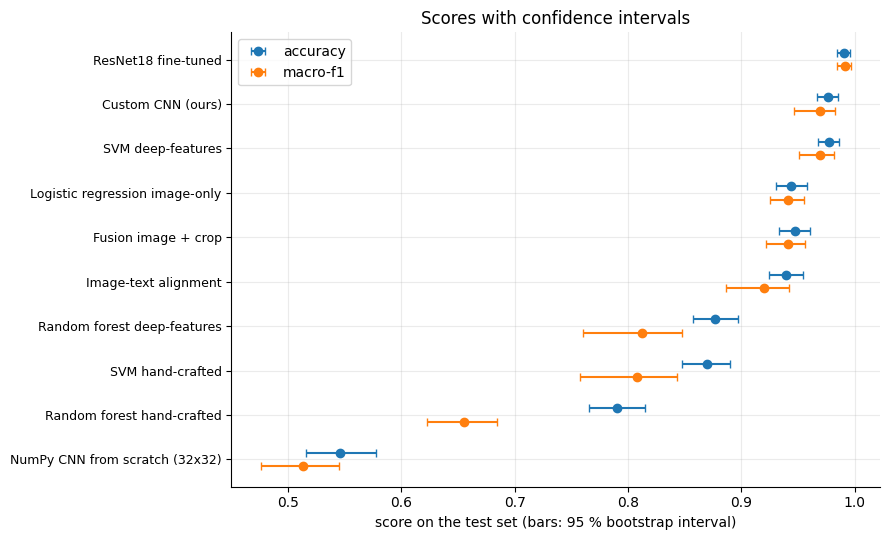

In [4]:
rng = np.random.default_rng(SEED)
boot_idx = rng.integers(0, N, size=(N_BOOT, N))
boot = {n: {"accuracy": np.empty(N_BOOT), "macro_f1": np.empty(N_BOOT)} for n in Yp}
for b, idx in enumerate(boot_idx):
    yt = y_true[idx]
    for n, yp in Yp.items():
        m = metrics_from_cm(confusion(yt, yp[idx], K))[0]
        boot[n]["accuracy"][b], boot[n]["macro_f1"][b] = m["accuracy"], m["macro_f1"]

ci = []
for n in table["model"]:
    row = {"model": n}
    for met in ["accuracy", "macro_f1"]:
        lo, hi = np.percentile(boot[n][met], [2.5, 97.5])
        row[met], row[met + "_low"], row[met + "_high"] = table.set_index("model").loc[n, met], lo, hi
    ci.append(row)
ci = pd.DataFrame(ci)
ci.to_csv(RESULTS / "bootstrap_confidence_intervals.csv", index=False)
display(ci.round(4))

fig, ax = plt.subplots(figsize=(9, 5.5))
yy = np.arange(len(ci))[::-1]
for off, met, colour in [(0.15, "accuracy", "tab:blue"), (-0.15, "macro_f1", "tab:orange")]:
    ax.errorbar(ci[met], yy + off, xerr=[ci[met] - ci[met + "_low"], ci[met + "_high"] - ci[met]], fmt="o", color=colour,
                capsize=3, label=met.replace("_", "-"))
ax.set_yticks(yy); ax.set_yticklabels(ci["model"], fontsize=9)
ax.set_xlabel("score on the test set (bars: 95 % bootstrap interval)")
ax.set_title("Scores with confidence intervals"); ax.legend(loc="upper left")
save_show("confidence_intervals")

## Section 6 - Statistical Tests

### 6.1 Do the models differ at all? Cochran's Q test

Before comparing pairs, Cochran's Q (formula in Section 2) tests the global hypothesis that all models are equally accurate. If it is not significant, differences between individual pairs should not be over-interpreted. The test uses the binary matrix of per-image correctness (images $\times$ models).

In [5]:
correct = np.column_stack([(Yp[n] == y_true).astype(int) for n in Yp])          # (N, k)
k = correct.shape[1]
Cj, Ri, T_ = correct.sum(0), correct.sum(1), correct.sum()
den = k * T_ - (Ri ** 2).sum()
Q = (k - 1) * (k * (Cj ** 2).sum() - T_ ** 2) / den if den > 0 else 0.0
p_Q = stats.chi2.sf(Q, k - 1)
print(f"Cochran's Q = {Q:.1f}, df = {k - 1}, p = {p_Q:.3g}")
print("->", "the models do NOT all have the same accuracy" if p_Q < ALPHA else "no evidence that the models differ")

Cochran's Q = 1873.9, df = 9, p = 0
-> the models do NOT all have the same accuracy


### 6.2 Which pairs differ? McNemar's test with Holm correction

For every pair of models the test of Section 2 is applied to the images on which exactly one of them is correct. For each pair the table lists $b$ and $c$, the difference in accuracy, the raw $p$-value, and the Holm-adjusted $p$-value. The matrix then shows, for each pair (row model minus column model), the accuracy difference, with a star where the Holm-adjusted $p$-value is below 0.05.

45 pairwise comparisons, 39 significant after Holm correction (alpha = 0.05)


,model_A,model_B,only_A_correct,only_B_correct,accuracy_diff,p_value,p_holm,significant
32,NumPy CNN from scratch (32x32),ResNet18 fine-tuned,3,456,-0.4441,0.0,0.0,True
3,Custom CNN (ours),NumPy CNN from scratch (32x32),446,7,0.4304,0.0,0.0,True
33,NumPy CNN from scratch (32x32),SVM deep-features,10,450,-0.4314,0.0,0.0,True
11,Fusion image + crop,NumPy CNN from scratch (32x32),429,20,0.4010,0.0,0.0,True
24,Logistic regression image-only,NumPy CNN from scratch (32x32),427,21,0.3980,0.0,0.0,True
18,Image-text alignment,NumPy CNN from scratch (32x32),422,21,0.3931,0.0,0.0,True
34,NumPy CNN from scratch (32x32),SVM hand-crafted,45,375,-0.3235,0.0,0.0,True
30,NumPy CNN from scratch (32x32),Random forest deep-features,51,388,-0.3304,0.0,0.0,True
39,Random forest hand-crafted,ResNet18 fine-tuned,4,208,-0.2000,0.0,0.0,True
5,Custom CNN (ours),Random forest hand-crafted,201,11,0.1863,0.0,0.0,True


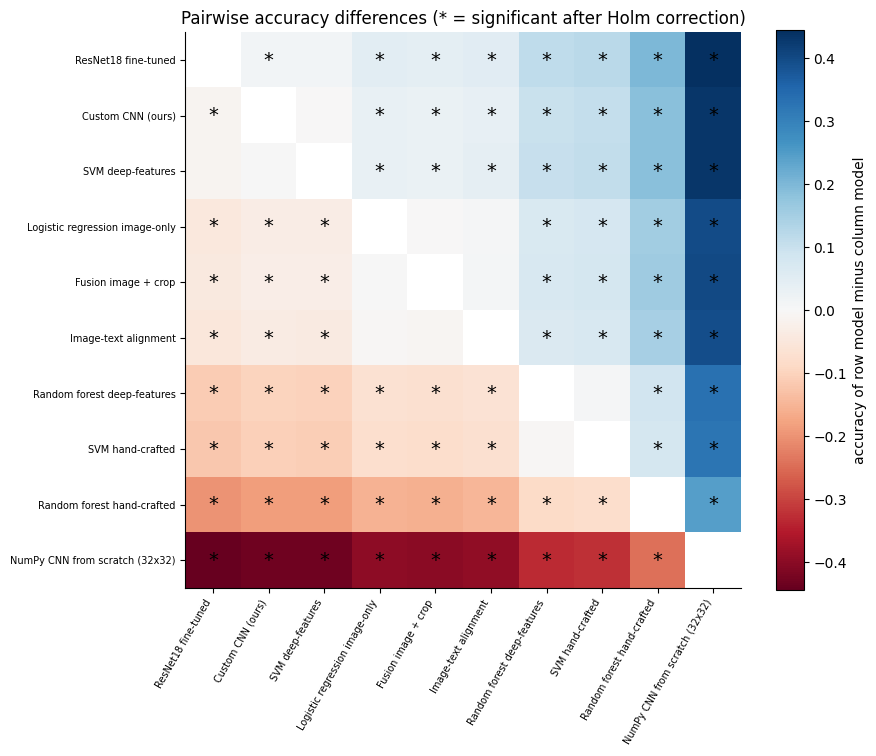

In [6]:
def mcnemar(ca, cb):
    b = int(((ca == 1) & (cb == 0)).sum())      # only A correct
    c = int(((ca == 0) & (cb == 1)).sum())      # only B correct
    if b + c == 0:
        return b, c, 1.0
    if b + c < 25:
        return b, c, stats.binomtest(min(b, c), b + c, 0.5).pvalue
    chi2 = (abs(b - c) - 1) ** 2 / (b + c)
    return b, c, stats.chi2.sf(chi2, 1)

def holm(pvals):
    p = np.asarray(pvals, float); m = len(p)
    order = np.argsort(p); adj = np.empty(m)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p[i]))
        adj[i] = running
    return adj

models = list(Yp)
cvec = {n: (Yp[n] == y_true).astype(int) for n in models}
pairs = list(combinations(models, 2))
res = []
for a, b_ in pairs:
    b, c, p = mcnemar(cvec[a], cvec[b_])
    res.append(dict(model_A=a, model_B=b_, only_A_correct=b, only_B_correct=c,
                    accuracy_diff=(cvec[a].mean() - cvec[b_].mean()), p_value=p))
pair_df = pd.DataFrame(res)
pair_df["p_holm"] = holm(pair_df["p_value"])
pair_df["significant"] = pair_df["p_holm"] < ALPHA
pair_df.to_csv(RESULTS / "mcnemar_all_pairs.csv", index=False)
print(f"{len(pair_df)} pairwise comparisons, {int(pair_df['significant'].sum())} significant after Holm correction (alpha = {ALPHA})")
display(pair_df.sort_values("p_holm").head(12).round(4))

order = table["model"].tolist()
M = np.full((len(order), len(order)), np.nan); S = np.zeros_like(M, bool)
look = {(r.model_A, r.model_B): r for r in pair_df.itertuples()}
for i, a in enumerate(order):
    for j, b_ in enumerate(order):
        if i == j: continue
        r = look.get((a, b_)) or look.get((b_, a))
        sign = 1 if (a, b_) in look else -1
        M[i, j], S[i, j] = sign * r.accuracy_diff, r.significant
fig, ax = plt.subplots(figsize=(9, 7.5))
lim = np.nanmax(np.abs(M)) or 1
im = ax.imshow(M, cmap="RdBu", vmin=-lim, vmax=lim)
for i in range(len(order)):
    for j in range(len(order)):
        if S[i, j]:
            ax.text(j, i, "*", ha="center", va="center", fontsize=14)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=7); ax.grid(False)
fig.colorbar(im, ax=ax, label="accuracy of row model minus column model")
ax.set_title("Pairwise accuracy differences (* = significant after Holm correction)")
save_show("mcnemar_matrix")

### 6.3 Targeted comparisons that answer the project's questions

The benchmark notebook was designed in pairs, each changing one factor. These planned comparisons are tested separately, because they answer specific questions, and each gets a **paired bootstrap 95 % interval** for the difference in accuracy and in macro-F1 (computed from the same resamples as in Section 5). Holm correction is applied across this smaller family. A pair is listed only if both models are available.

,question,model_A,model_B,only_A_correct,only_B_correct,acc_diff,acc_diff_low,acc_diff_high,f1_diff,f1_diff_low,f1_diff_high,p_value,p_holm,significant
0,Does learning the features help? (SVM),SVM hand-crafted,SVM deep-features,17,127,-0.1078,-0.1304,-0.0853,-0.1608,-0.2126,-0.1208,0.0000,0.0000,True
1,Does learning the features help? (forest),Random forest hand-crafted,Random forest deep-features,49,137,-0.0863,-0.1127,-0.0618,-0.1568,-0.1997,-0.1015,0.0000,0.0000,True
2,Margin classifier or tree ensemble? (hand-craf...,SVM hand-crafted,Random forest hand-crafted,132,51,0.0794,0.0529,0.1049,0.1525,0.0968,0.1968,0.0000,0.0000,True
3,Margin classifier or tree ensemble? (deep),SVM deep-features,Random forest deep-features,111,8,0.1010,0.0814,0.1196,0.1565,0.1177,0.2092,0.0000,0.0000,True
4,Does pretraining help?,ResNet18 fine-tuned,Custom CNN (ours),19,5,0.0137,0.0049,0.0235,0.0220,0.0078,0.0433,0.0066,0.0264,True
5,Does fine-tuning beat frozen features?,ResNet18 fine-tuned,SVM deep-features,23,10,0.0127,0.0020,0.0235,0.0220,0.0071,0.0406,0.0367,0.1101,False
6,Does the crop metadata help?,Fusion image + crop,Logistic regression image-only,8,5,0.0029,-0.0039,0.0098,-0.0004,-0.0144,0.0103,0.5811,0.9450,False
7,Does text alignment match a plain classifier?,Image-text alignment,Logistic regression image-only,13,18,-0.0049,-0.0157,0.0059,-0.0217,-0.0512,-0.0000,0.4725,0.9450,False
8,Small NumPy CNN vs custom CNN,NumPy CNN from scratch (32x32),Custom CNN (ours),7,446,-0.4304,-0.4618,-0.3980,-0.4559,-0.4935,-0.4205,0.0000,0.0000,True


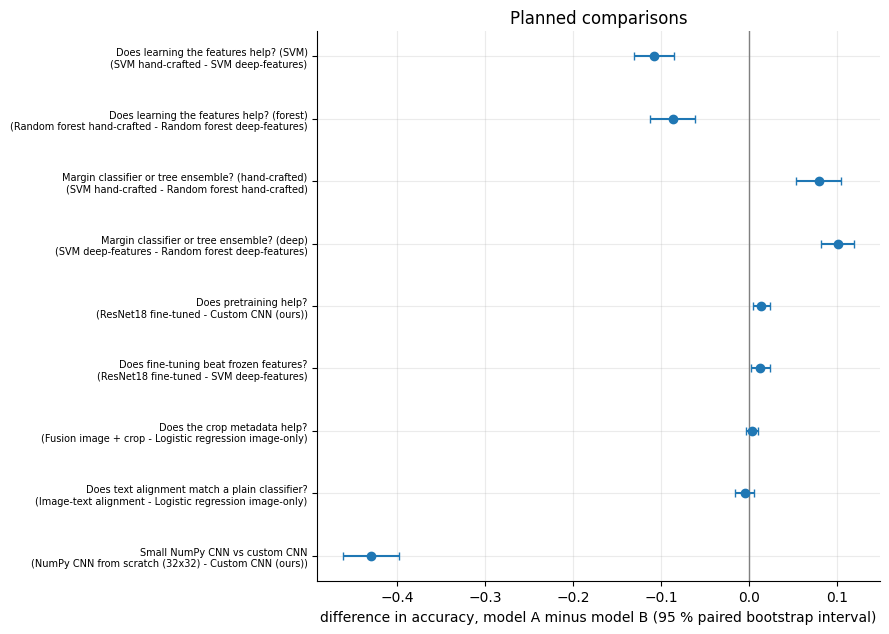

In [7]:
planned = [
    ("Does learning the features help? (SVM)", "SVM hand-crafted", "SVM deep-features"),
    ("Does learning the features help? (forest)", "Random forest hand-crafted", "Random forest deep-features"),
    ("Margin classifier or tree ensemble? (hand-crafted)", "SVM hand-crafted", "Random forest hand-crafted"),
    ("Margin classifier or tree ensemble? (deep)", "SVM deep-features", "Random forest deep-features"),
    ("Does pretraining help?", "ResNet18 fine-tuned", "Custom CNN (ours)"),
    ("Does fine-tuning beat frozen features?", "ResNet18 fine-tuned", "SVM deep-features"),
    ("Does the crop metadata help?", "Fusion image + crop", "Logistic regression image-only"),
    ("Does text alignment match a plain classifier?", "Image-text alignment", "Logistic regression image-only"),
    ("Does class weighting help?", "Custom CNN, class-weighted", "Custom CNN (ours)"),
    ("Small NumPy CNN vs custom CNN", "NumPy CNN from scratch (32x32)", "Custom CNN (ours)"),
]
rows = []
for question, a, b_ in planned:
    if a not in Yp or b_ not in Yp:
        continue
    nb_, nc_, p = mcnemar(cvec[a], cvec[b_])
    d_acc = boot[a]["accuracy"] - boot[b_]["accuracy"]
    d_f1 = boot[a]["macro_f1"] - boot[b_]["macro_f1"]
    rows.append(dict(question=question, model_A=a, model_B=b_, only_A_correct=nb_, only_B_correct=nc_,
                     acc_diff=cvec[a].mean() - cvec[b_].mean(), acc_diff_low=np.percentile(d_acc, 2.5), acc_diff_high=np.percentile(d_acc, 97.5),
                     f1_diff=table.set_index("model").loc[a, "macro_f1"] - table.set_index("model").loc[b_, "macro_f1"],
                     f1_diff_low=np.percentile(d_f1, 2.5), f1_diff_high=np.percentile(d_f1, 97.5), p_value=p))
planned_df = pd.DataFrame(rows)
if len(planned_df):
    planned_df["p_holm"] = holm(planned_df["p_value"])
    planned_df["significant"] = planned_df["p_holm"] < ALPHA
    planned_df.to_csv(RESULTS / "planned_comparisons.csv", index=False)
    display(planned_df.round(4))

    fig, ax = plt.subplots(figsize=(9, 0.55 * len(planned_df) + 1.5))
    yy = np.arange(len(planned_df))[::-1]
    ax.errorbar(planned_df["acc_diff"], yy, xerr=[planned_df["acc_diff"] - planned_df["acc_diff_low"], planned_df["acc_diff_high"] - planned_df["acc_diff"]],
                fmt="o", color="tab:blue", capsize=3)
    ax.axvline(0, color="gray", lw=1)
    ax.set_yticks(yy); ax.set_yticklabels([f"{r.question}\n({r.model_A} - {r.model_B})" for r in planned_df.itertuples()], fontsize=7)
    ax.set_xlabel("difference in accuracy, model A minus model B (95 % paired bootstrap interval)")
    ax.set_title("Planned comparisons")
    save_show("planned_comparisons")
else:
    print("None of the planned model pairs is available yet - run the benchmark and custom CNN notebooks.")

**How to read it.** An interval that includes 0 means the data do not show a reliable difference in accuracy between the two models, even if one score is a little higher. The significance test and the interval address the same question in two ways and usually agree. They can differ when the number of images on which the two models disagree is small, and because the Holm correction is applied to the $p$-values but not to the intervals; in that case trust the corrected test and describe the evidence as weak. A *statistically significant* difference can also be *practically small*: look at the size of the difference as well as the $p$-value.

## Section 7 - Per-Class Analysis

Overall scores average over classes. The heat map shows the **F1 score of every model on every class**, with classes sorted from hardest to easiest (by the mean over models). A row that is pale for all models marks a class that is hard for the data as such (few training images or a look-alike class), not for one method.

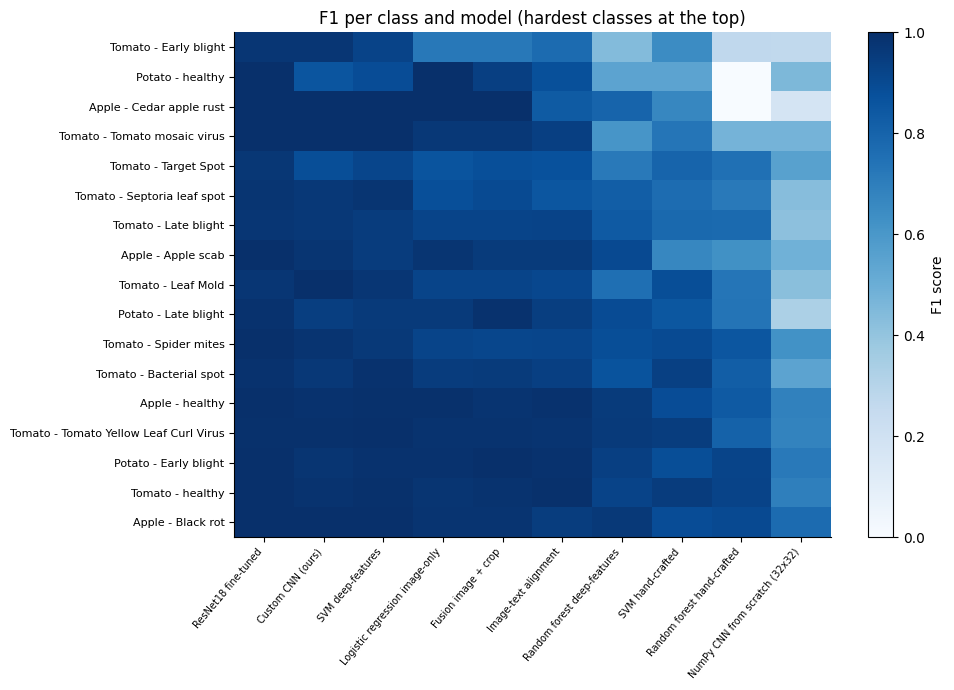

,Tomato - Early blight,Potato - healthy,Apple - Cedar apple rust,Tomato - Tomato mosaic virus,Tomato - Target Spot
mean F1 over models,0.67,0.711,0.748,0.816,0.821


In [8]:
pc = pd.DataFrame(per_class_f1, index=class_names)[table["model"].tolist()]
pc = pc.loc[pc.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(pc.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(pc.shape[1])); ax.set_xticklabels(pc.columns, rotation=50, ha="right", fontsize=7)
ax.set_yticks(range(pc.shape[0])); ax.set_yticklabels(pc.index, fontsize=8); ax.grid(False)
fig.colorbar(im, ax=ax, label="F1 score"); ax.set_title("F1 per class and model (hardest classes at the top)")
save_show("per_class_f1_heatmap")
pc.round(3).to_csv(RESULTS / "per_class_f1.csv")
display(pc.mean(axis=1).rename("mean F1 over models").round(3).head(5).to_frame().T)

**Does class size explain the difficulty?** The Spearman rank correlation $\rho$ between the number of *training* images of a class and its F1 score tests the effect of the class imbalance. A clearly positive $\rho$ means small classes are systematically worse; near zero means other factors (such as visual similarity) matter more. It is computed per model.

,model,Spearman rho (class size vs F1),p-value
0,ResNet18 fine-tuned,-0.418,0.095
1,Custom CNN (ours),-0.226,0.383
2,SVM deep-features,0.012,0.962
3,Logistic regression image-only,-0.380,0.133
4,Fusion image + crop,-0.162,0.534
5,Image-text alignment,0.221,0.394
6,Random forest deep-features,0.342,0.180
7,SVM hand-crafted,0.627,0.007
8,Random forest hand-crafted,0.518,0.033
9,NumPy CNN from scratch (32x32),0.224,0.388


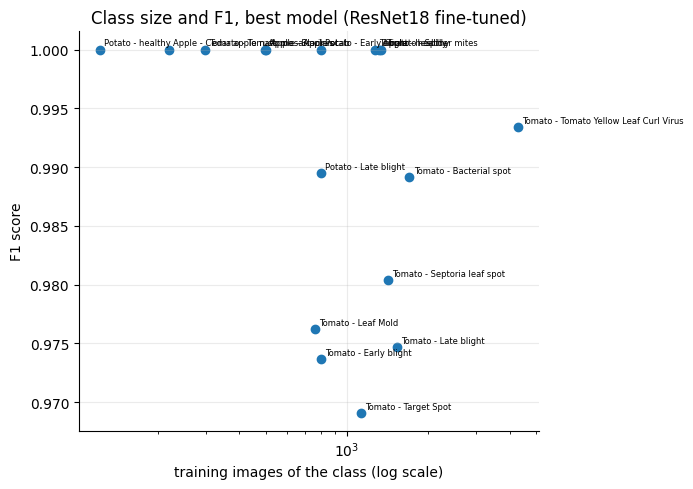

In [9]:
rows = []
for n in table["model"]:
    rho, p = stats.spearmanr(train_counts, per_class_f1[n])
    rows.append((n, rho, p))
sz = pd.DataFrame(rows, columns=["model", "Spearman rho (class size vs F1)", "p-value"])
display(sz.round(3))

fig, ax = plt.subplots(figsize=(7, 5))
best = table.loc[0, "model"]
ax.scatter(train_counts, per_class_f1[best], color="tab:blue")
for x_, y_, n in zip(train_counts, per_class_f1[best], class_names):
    ax.annotate(n, (x_, y_), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("training images of the class (log scale)"); ax.set_ylabel("F1 score")
ax.set_title(f"Class size and F1, best model ({best})")
save_show("class_size_vs_f1")

## Section 8 - Error Analysis

**Which classes get confused?** The row-normalised confusion matrix of the best model shows, for each true class, where its images go. Entries off the diagonal are errors; look for pairs of similar diseases.

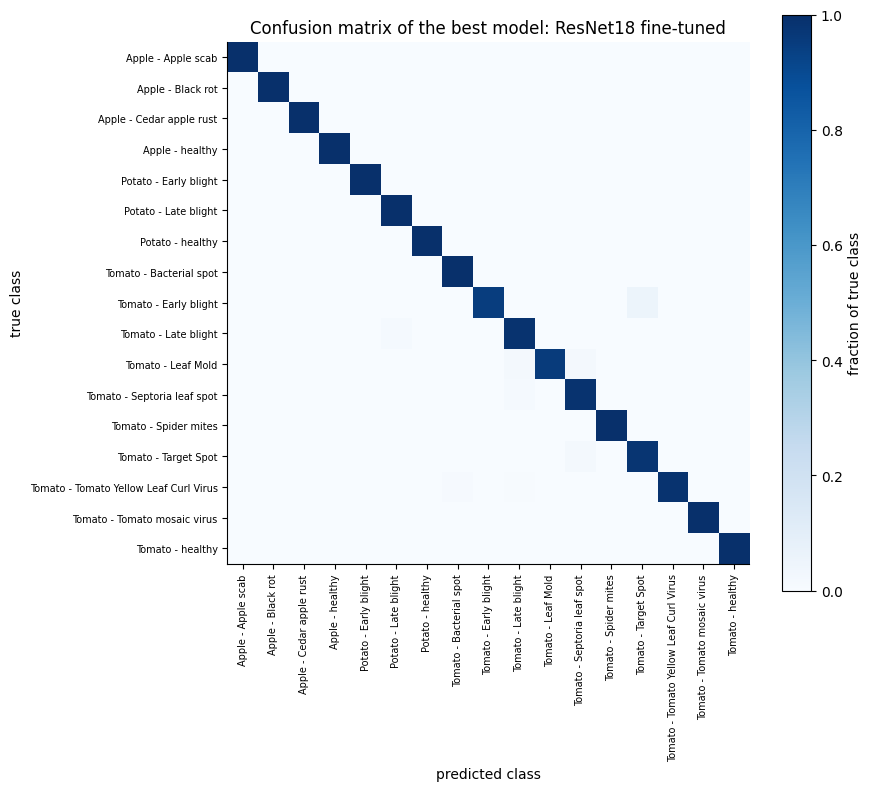

Most frequent confusions of the best model (true -> predicted):


,true class,predicted as,images
0,Tomato - Early blight,Tomato - Target Spot,2
6,Tomato - Tomato Yellow Leaf Curl Virus,Tomato - Bacterial spot,2
1,Tomato - Late blight,Potato - Late blight,1
2,Tomato - Leaf Mold,Tomato - Late blight,1
3,Tomato - Leaf Mold,Tomato - Septoria leaf spot,1
4,Tomato - Septoria leaf spot,Tomato - Late blight,1
5,Tomato - Target Spot,Tomato - Septoria leaf spot,1
7,Tomato - Tomato Yellow Leaf Curl Virus,Tomato - Late blight,1


In [10]:
best = table.loc[0, "model"]
C = confusion(y_true, Yp[best], K)
Cn = C / C.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(Cn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_xticklabels(class_names, rotation=90, fontsize=7)
ax.set_yticks(range(K)); ax.set_yticklabels(class_names, fontsize=7); ax.grid(False)
ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.set_title(f"Confusion matrix of the best model: {best}")
fig.colorbar(im, ax=ax, label="fraction of true class")
save_show("confusion_best_model")

off = [(class_names[i], class_names[j], int(C[i, j])) for i in range(K) for j in range(K) if i != j and C[i, j] > 0]
print("Most frequent confusions of the best model (true -> predicted):")
display(pd.DataFrame(off, columns=["true class", "predicted as", "images"]).sort_values("images", ascending=False).head(8))

**What kind of errors do the models make?** Errors have different practical meaning:

* a **cross-crop error** (predicting a disease of another crop) is the most serious, because the crop is known to the grower;
* a **healthy/diseased error** is serious for disease management: calling a diseased leaf healthy (a *missed disease*) is worse than the reverse;
* an error between two diseases of the same crop is the mildest.

The table lists, for each model, the share of errors of each kind, the accuracy of the binary decision *healthy or diseased*, and the **disease detection rate** (share of diseased leaves not called healthy).

,model,errors,cross_crop_share,healthy_disease_error_share,healthy_vs_diseased_accuracy,disease_detection_rate,missed_diseases,false_alarms
0,ResNet18 fine-tuned,10,0.1000,0.0000,1.0000,1.0000,0,0
1,Custom CNN (ours),24,0.2917,0.0833,0.9961,0.9965,3,1
2,SVM deep-features,23,0.1304,0.1739,0.9961,0.9953,4,0
3,Logistic regression image-only,57,0.0877,0.0702,0.9961,0.9988,1,3
4,Fusion image + crop,54,0.0000,0.1111,0.9941,0.9965,3,3
5,Image-text alignment,62,0.1129,0.0645,0.9951,0.9965,3,2
6,Random forest deep-features,126,0.1667,0.1111,0.9843,0.9918,7,9
7,SVM hand-crafted,133,0.2331,0.1429,0.9696,0.9871,11,20
8,Random forest hand-crafted,214,0.2991,0.0841,0.9539,0.9694,26,21
9,NumPy CNN from scratch (32x32),463,0.3823,0.1080,0.9010,0.9506,42,59


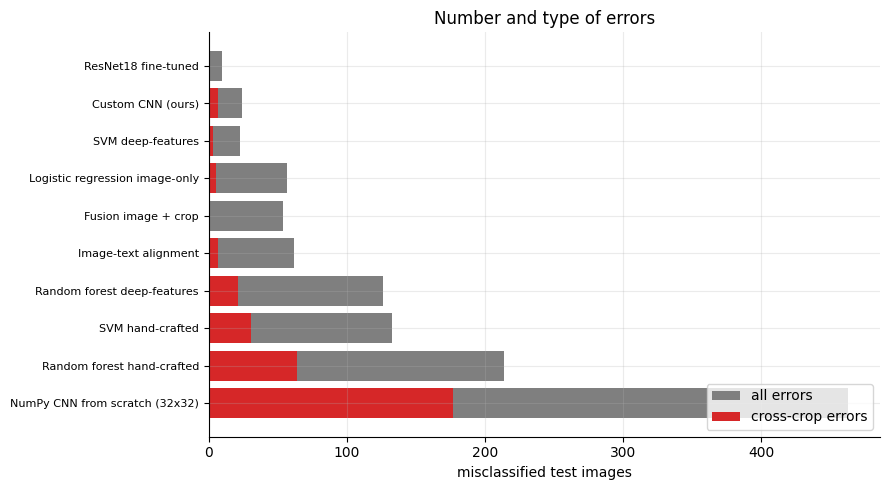

In [11]:
crop_arr = np.array(class_crop)
rows = []
for n in table["model"]:
    yp = Yp[n]
    err = yp != y_true
    cross = crop_arr[y_true] != crop_arr[yp]
    healthy_true, healthy_pred = class_healthy[y_true], class_healthy[yp]
    missed = (~healthy_true) & healthy_pred
    false_alarm = healthy_true & (~healthy_pred)
    rows.append(dict(model=n, errors=int(err.sum()),
                     cross_crop_share=(err & cross).sum() / max(err.sum(), 1),
                     healthy_disease_error_share=(err & (healthy_true != healthy_pred) & ~cross).sum() / max(err.sum(), 1),
                     healthy_vs_diseased_accuracy=(healthy_true == healthy_pred).mean(),
                     disease_detection_rate=1 - missed.sum() / max((~healthy_true).sum(), 1),
                     missed_diseases=int(missed.sum()), false_alarms=int(false_alarm.sum())))
errs = pd.DataFrame(rows)
errs.to_csv(RESULTS / "error_types.csv", index=False)
display(errs.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
yy = np.arange(len(errs))[::-1]
ax.barh(yy, errs["errors"], color="tab:gray", label="all errors")
ax.barh(yy, errs["cross_crop_share"] * errs["errors"], color="tab:red", label="cross-crop errors")
ax.set_yticks(yy); ax.set_yticklabels(errs["model"], fontsize=8); ax.set_xlabel("misclassified test images")
ax.set_title("Number and type of errors"); ax.legend(loc="lower right")
save_show("error_types")

**Which images are hard for everybody?** For every test image the number of models that classify it correctly is counted. The histogram shows how the images divide into *easy* (nearly all models right), *hard* (few models right) and *unsolved* (no model right). Images that **no** model classifies correctly are the best candidates for label errors or genuinely ambiguous leaves, and a sample of them is shown below.

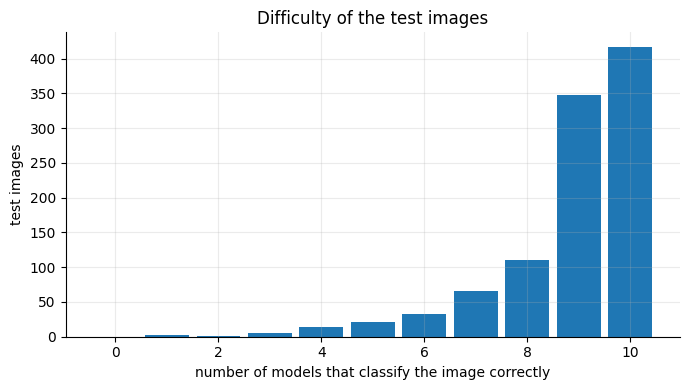

Images classified correctly by no model: 0 of 1020 (0.0%)


In [12]:
n_correct = correct.sum(axis=1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(n_correct, bins=np.arange(-0.5, k + 1.5, 1), color="tab:blue", rwidth=0.85)
ax.set_xlabel("number of models that classify the image correctly"); ax.set_ylabel("test images")
ax.set_title("Difficulty of the test images")
save_show("difficulty_histogram")

unsolved = np.where(n_correct == 0)[0]
print(f"Images classified correctly by no model: {len(unsolved)} of {N} ({len(unsolved) / N:.1%})")
if len(unsolved):
    show = unsolved[:8]
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.2))
    for ax in np.ravel(axes): ax.axis("off")
    for ax, i in zip(np.ravel(axes), show):
        ax.imshow(Image.open(ROOT_DIR / common[i]).convert("RGB"))
        votes = pd.Series([class_names[Yp[n][i]] for n in models]).value_counts().index[0]
        ax.set_title(f"true: {class_names[y_true[i]]}\nmost predicted: {votes}", fontsize=8)
    save_show("unsolved_images")

## Section 9 - Confidence and Calibration

A classifier is *well calibrated* when its confidence matches its accuracy: of the predictions made with 80 % confidence, about 80 % should be correct. This matters in practice, since a farmer needs to know when not to trust a diagnosis. The **expected calibration error** compares confidence and accuracy in $M$ confidence bins $B_m$ (Guo et al., 2017):

$$
\text{ECE}=\sum_{m=1}^{M}\frac{|B_m|}{N}\,\big|\operatorname{acc}(B_m)-\operatorname{conf}(B_m)\big| .
$$

Only the custom CNN notebook saved the model's confidence (the largest softmax probability), so this analysis covers that model. The reliability diagram plots accuracy against confidence (the dashed diagonal is perfect calibration); the histogram compares the confidence of correct and wrong predictions.

Expected calibration error of the custom CNN: 0.0058 | mean confidence 0.973 vs accuracy 0.976


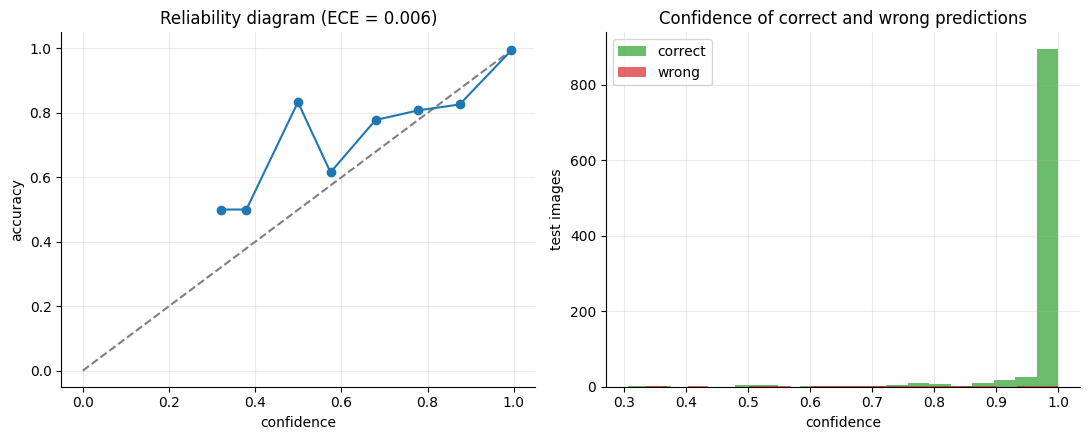

In [13]:
cnn_file = PRED_DIR / "custom_cnn_test_predictions.csv"
if cnn_file.exists() and "confidence" in pd.read_csv(cnn_file).columns:
    cp = pd.read_csv(cnn_file).drop_duplicates("path").set_index("path").loc[common]
    conf, ok = cp["confidence"].values, (cp["y_pred"].values == cp["y_true"].values)
    edges = np.linspace(1 / K, 1.0000001, 11)          # a softmax confidence is never below 1/K: 10 equal bins from 1/K to 1
    b = np.clip(np.digitize(conf, edges) - 1, 0, 9)
    acc_b = np.array([ok[b == i].mean() if (b == i).any() else np.nan for i in range(10)])
    conf_b = np.array([conf[b == i].mean() if (b == i).any() else np.nan for i in range(10)])
    cnt = np.array([(b == i).sum() for i in range(10)])
    ece = np.nansum(cnt / len(conf) * np.abs(acc_b - conf_b))
    print(f"Expected calibration error of the custom CNN: {ece:.4f} | mean confidence {conf.mean():.3f} vs accuracy {ok.mean():.3f}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ax[0].plot([0, 1], [0, 1], "--", color="gray")
    ax[0].plot(conf_b, acc_b, "o-", color="tab:blue")
    ax[0].set_xlabel("confidence"); ax[0].set_ylabel("accuracy"); ax[0].set_title(f"Reliability diagram (ECE = {ece:.3f})")
    ax[1].hist(conf[ok], bins=20, alpha=0.7, label="correct", color="tab:green")
    ax[1].hist(conf[~ok], bins=20, alpha=0.7, label="wrong", color="tab:red")
    ax[1].set_xlabel("confidence"); ax[1].set_ylabel("test images"); ax[1].set_title("Confidence of correct and wrong predictions"); ax[1].legend()
    save_show("calibration_custom_cnn")
else:
    print("No confidence values found - run custom_cnn.ipynb to include this analysis.")

## Section 10 - Quality Versus Cost

The best model is not only the most accurate one: training time, model size and prediction cost matter for a tool that should run on a phone. The cell collects these costs from the files written by the earlier notebooks (`results/benchmarks/benchmark_comparison.csv` and the metrics of the from-scratch network), adds the ranks by macro-F1 and MCC, and plots macro-F1 against the total prediction time per image (feature extraction plus classifier).

,model,accuracy,macro_f1,mcc,train_time_s,predict_ms_per_image,size,rank_macro_f1,rank_mcc
0,ResNet18 fine-tuned,0.9902,0.9909,0.9891,1680.2386,6.3470,"11,185,233 parameters",1,1
1,Custom CNN (ours),0.9765,0.9690,0.9739,9322.7925,10.1051,"1,442,097 parameters",2,3
2,SVM deep-features,0.9775,0.9690,0.9750,7.1414,7.3723,"C=10, 9320 support vectors",3,2
3,Logistic regression image-only,0.9441,0.9414,0.9380,2.6600,6.0415,"8,721 parameters",4,5
4,Fusion image + crop,0.9471,0.9409,0.9413,2.2797,6.0224,"8,772 parameters",5,4
5,Image-text alignment,0.9392,0.9196,0.9326,1.9278,6.0215,"58,881 parameters",6,6
6,Random forest deep-features,0.8765,0.8125,0.8629,17.4952,6.0629,"300 trees, 1,940,974 nodes",7,7
7,SVM hand-crafted,0.8696,0.8082,0.8550,26.3618,11.8318,"C=10, 14765 support vectors",8,8
8,Random forest hand-crafted,0.7902,0.6557,0.7671,35.6421,9.6168,"300 trees, 2,346,096 nodes",9,9
9,NumPy CNN from scratch (32x32),0.5461,0.5131,0.5132,14.8787,0.4504,"68,097 parameters",10,10


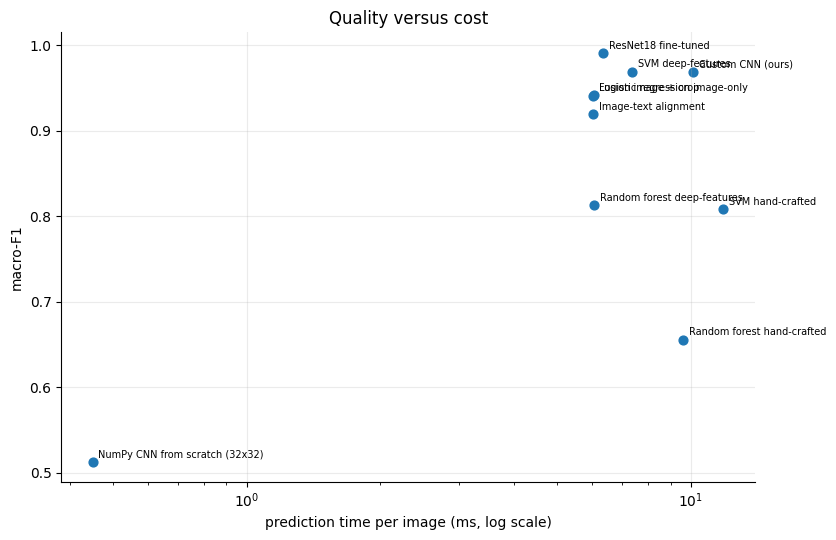

In [14]:
cost = pd.DataFrame(columns=["model", "train_time_s", "predict_ms_per_image", "size"])
bf = BENCH_DIR / "benchmark_comparison.csv"
if bf.exists():
    b = pd.read_csv(bf)
    cost = pd.DataFrame({"model": b["model"], "train_time_s": b["train_time_s"],
                         "predict_ms_per_image": b["feature_ms_per_image"] + b["classifier_ms_per_image"], "size": b["size"]})
sf = PRED_DIR / "numpy_cnn_from_scratch_metrics.json"
if sf.exists():
    m = json.load(open(sf))
    cost = pd.concat([cost, pd.DataFrame([dict(model=NAMES["numpy_cnn_from_scratch"], train_time_s=m["train_time_s"],
                                               predict_ms_per_image=m["infer_ms_per_image"], size=f"{m['parameters']:,} parameters")])])
cost = cost.drop_duplicates("model")

score = table.merge(cost, on="model", how="left")
score["rank_macro_f1"] = score["macro_f1"].rank(ascending=False, method="min").astype(int)
score["rank_mcc"] = score["mcc"].rank(ascending=False, method="min").astype(int)
score["rank_speed"] = score["predict_ms_per_image"].rank(method="min")
score.to_csv(RESULTS / "scorecard.csv", index=False)
display(score[["model", "accuracy", "macro_f1", "mcc", "train_time_s", "predict_ms_per_image", "size", "rank_macro_f1", "rank_mcc"]].round(4))

ok_ = score.dropna(subset=["predict_ms_per_image"])
if len(ok_):
    fig, ax = plt.subplots(figsize=(8.5, 5.5))
    ax.scatter(ok_["predict_ms_per_image"], ok_["macro_f1"], s=40, color="tab:blue")
    for r in ok_.itertuples():
        ax.annotate(r.model, (r.predict_ms_per_image, r.macro_f1), fontsize=7, xytext=(4, 3), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("prediction time per image (ms, log scale)"); ax.set_ylabel("macro-F1")
    ax.set_title("Quality versus cost")
    save_show("quality_vs_cost")

## Section 11 - Findings of the Project

The cell below writes the main findings **from the numbers of this run** (best model, significant and non-significant comparisons, effect of the added modalities, error types), so the text always agrees with the tables above. Use these sentences as the starting point of the discussion in the report, and add your own interpretation of *why* the results look as they do (for example from the literature review).

In [15]:
tb = table.set_index("model")
lines = []
b0 = table.loc[0, "model"]
r0 = ci.set_index("model").loc[b0]
lines.append(f"Best model by macro-F1: {b0} (macro-F1 {tb.loc[b0, 'macro_f1']:.3f}, 95% interval {r0['macro_f1_low']:.3f}-{r0['macro_f1_high']:.3f}; "
             f"accuracy {tb.loc[b0, 'accuracy']:.3f}; MCC {tb.loc[b0, 'mcc']:.3f}).")
lines.append(f"Cochran's Q test: {'the models differ significantly' if p_Q < ALPHA else 'no significant difference between the models'} (p = {p_Q:.3g}).")
lines.append(f"{int(pair_df['significant'].sum())} of {len(pair_df)} pairwise differences are significant after Holm correction.")
top2 = table.loc[1, "model"] if len(table) > 1 else None
if top2:
    r = pair_df[((pair_df.model_A == b0) & (pair_df.model_B == top2)) | ((pair_df.model_A == top2) & (pair_df.model_B == b0))].iloc[0]
    lines.append(f"The two best models ({b0} and {top2}) are {'significantly different' if r.significant else 'not significantly different'} "
                 f"(Holm-adjusted p = {r.p_holm:.3g}).")
if len(planned_df):
    for r in planned_df.itertuples():
        direction = "higher" if r.acc_diff > 0 else "lower"
        verdict = "significant" if r.significant else "not significant"
        lines.append(f"{r.question} {r.model_A} has {abs(r.acc_diff) * 100:.2f} percentage points {direction} accuracy than {r.model_B} "
                     f"(95% interval {r.acc_diff_low * 100:.2f} to {r.acc_diff_high * 100:.2f}; {verdict}, Holm p = {r.p_holm:.3g}).")
worst = pc.index[:3].tolist()
lines.append(f"Hardest classes (lowest mean F1 over all models): {', '.join(worst)}.")
lines.append(f"Test images that no model classifies correctly: {len(unsolved)} of {N} ({len(unsolved) / N:.1%}).")
e0 = errs.set_index("model").loc[b0]
lines.append(f"For {b0}: {e0['cross_crop_share']:.0%} of the errors are cross-crop errors; disease detection rate {e0['disease_detection_rate']:.3f}; "
             f"{int(e0['missed_diseases'])} diseased leaves were called healthy.")
zf = BENCH_DIR / "zero_shot_results.csv"
if zf.exists():
    z = pd.read_csv(zf)
    lines.append(f"Zero-shot classification from text alone reached a mean top-1 accuracy of {z['zero-shot top-1'].mean():.3f} "
                 f"(chance {1 / K:.3f}) and top-3 of {z['zero-shot top-3'].mean():.3f} (chance {3 / K:.3f}) on classes never seen in training.")
for l in lines:
    print("-", l)
open(RESULTS / "findings.txt", "w").write("\n".join(lines))

- Best model by macro-F1: ResNet18 fine-tuned (macro-F1 0.991, 95% interval 0.984-0.996; accuracy 0.990; MCC 0.989).
- Cochran's Q test: the models differ significantly (p = 0).
- 39 of 45 pairwise differences are significant after Holm correction.
- The two best models (ResNet18 fine-tuned and Custom CNN (ours)) are significantly different (Holm-adjusted p = 0.0463).
- Does learning the features help? (SVM) SVM hand-crafted has 10.78 percentage points lower accuracy than SVM deep-features (95% interval -13.04 to -8.53; significant, Holm p = 7.37e-19).
- Does learning the features help? (forest) Random forest hand-crafted has 8.63 percentage points lower accuracy than Random forest deep-features (95% interval -11.27 to -6.18; significant, Holm p = 1.07e-09).
- Margin classifier or tree ensemble? (hand-crafted) SVM hand-crafted has 7.94 percentage points higher accuracy than Random forest hand-crafted (95% interval 5.29 to 10.49; significant, Holm p = 1.67e-08).
- Margin classifier or t

2588

**Capstone summary.** The project set out to solve a complex problem, recognising plant diseases from leaf images, with computer vision and multi-modal machine learning. The notebooks together show the full chain: a multi-modal dataset (image, text, metadata) was built and analysed; images were preprocessed and features extracted; a custom CNN was designed, trained and implemented from scratch; seven benchmarks covering classical, transfer-learning and multi-modal methods were trained on identical splits; and this notebook evaluated all models with appropriate metrics, visualisations and statistical tests. In the report, answer the project's questions with the findings above:

1. *Do learned features beat hand-crafted ones?* (planned comparisons 1 and 2)
2. *Which classifier family is better, margin-based or tree-based?* (comparisons 3 and 4)
3. *What does pretraining add over a CNN trained from scratch?* (comparison 5)
4. *Does a second modality help?* (comparisons 7 and 8, error types)
5. *Can text descriptions recognise unseen diseases?* (zero-shot result)
6. *What does it cost?* (Section 10)

## Section 12 - Limitations of This Analysis

* **One test set, one split, one seed.** The bootstrap interval measures variation due to *which test images* were drawn, but not variation due to *training* (different seeds or different splits). Repeating the training with several seeds, or using repeated cross-validation, would be needed to capture that.
* **Independence assumption.** McNemar's test, Cochran's Q and the bootstrap assume the test images are independent. PlantVillage contains several photographs of the same leaf; if near-duplicates fall in the test set (and in the training set), scores are inflated and the effective sample size is smaller than $N$, so $p$-values are somewhat too small and intervals too narrow.
* **Multiple comparisons.** Holm correction controls false positives within each family of tests, but running several families (all pairs, planned pairs) still increases the overall chance of a spurious finding; the planned comparisons were chosen before the results were known, which is why they deserve more weight than a search over all pairs.
* **Significance is not importance.** With thousands of test images, tiny differences can be significant while being irrelevant in practice; report the size of the difference and its interval.
* **Different effort per model.** Hyper-parameter tuning was deliberately small and unequal (for example, a simple grid for the SVM, 5 epochs for ResNet18), so a ranking reflects these settings, not the best possible version of each method. The NumPy network works on much smaller images.
* **Calibration** was analysed for one model only because only its confidence values were saved.
* **External validity.** All results are on PlantVillage test images with uniform backgrounds; the literature review shows that accuracy on field photographs is far lower, so none of these numbers predicts real-world performance.

## Section 13 - Saved Outputs

In [16]:
for f in sorted(RESULTS.glob("*")):
    print(f.relative_to(ROOT_DIR))

results/analysis/bootstrap_confidence_intervals.csv
results/analysis/calibration_custom_cnn.png
results/analysis/class_size_vs_f1.png
results/analysis/confidence_intervals.png
results/analysis/confusion_best_model.png
results/analysis/difficulty_histogram.png
results/analysis/error_types.csv
results/analysis/error_types.png
results/analysis/findings.txt
results/analysis/mcnemar_all_pairs.csv
results/analysis/mcnemar_matrix.png
results/analysis/metrics_all_models.csv
results/analysis/per_class_f1.csv
results/analysis/per_class_f1_heatmap.png
results/analysis/planned_comparisons.csv
results/analysis/planned_comparisons.png
results/analysis/quality_vs_cost.png
results/analysis/scorecard.csv


## References

Cochran, W. G. 1950, The comparison of percentages in matched samples, *Biometrika*, vol. 37, pp. 256-266.

Dietterich, T. G. 1998, Approximate statistical tests for comparing supervised classification learning algorithms, *Neural Computation*, vol. 10, no. 7, pp. 1895-1923.

Efron, B. & Tibshirani, R. J. 1993, *An Introduction to the Bootstrap*, Chapman & Hall, New York.

Gorodkin, J. 2004, Comparing two K-category assignments by a K-category correlation coefficient, *Computational Biology and Chemistry*, vol. 28, pp. 367-374.

Guo, C., Pleiss, G., Sun, Y. & Weinberger, K. Q. 2017, On calibration of modern neural networks, *Proceedings of the 34th International Conference on Machine Learning*, PMLR 70, pp. 1321-1330.

Holm, S. 1979, A simple sequentially rejective multiple test procedure, *Scandinavian Journal of Statistics*, vol. 6, pp. 65-70.

McNemar, Q. 1947, Note on the sampling error of the difference between correlated proportions or percentages, *Psychometrika*, vol. 12, pp. 153-157.

Sokolova, M. & Lapalme, G. 2009, A systematic analysis of performance measures for classification tasks, *Information Processing and Management*, vol. 45, pp. 427-437.